# Deep Learning — Task E

## AI Powered E-Commerce Customer Intelligence System

This notebook uses the same churn dataset definition and the same train/test split as Task D. It builds one small feed-forward neural network with a 32 → 16 → 1 architecture and compares it with Logistic Regression and Random Forest.

### Hackathon requirements
- Same churn dataset and test data.
- Small feed-forward neural network such as 32 → 16 → 1.
- Suitable activation functions and binary classification loss.
- Accuracy, Precision, Recall, F1-score, Confusion Matrix and ROC-AUC.
- Compare with Logistic Regression and Random Forest.
- Explain whether Deep Learning was worth the additional complexity.


In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, classification_report
)
import joblib

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## 1. Load the SQLite database


In [2]:
NOTEBOOK_DIR = Path.cwd()
possible_paths = [
    NOTEBOOK_DIR / 'ecommerce_hackathon.db',
    NOTEBOOK_DIR.parent / 'ecommerce_hackathon.db',
    NOTEBOOK_DIR.parent.parent / 'ecommerce_hackathon.db',
]
DB_PATH = next((p for p in possible_paths if p.exists()), None)

if DB_PATH is None:
    raise FileNotFoundError(
        'ecommerce_hackathon.db was not found. Put it in the notebook folder '
        'or one/two folders above it.'
    )

print('Database:', DB_PATH.resolve())

conn = sqlite3.connect(DB_PATH)
customers = pd.read_sql_query('SELECT * FROM customers;', conn)
orders = pd.read_sql_query('SELECT * FROM orders;', conn)
conn.close()

print('Customers shape:', customers.shape)
print('Orders shape:', orders.shape)


Database: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\ecommerce_hackathon.db
Customers shape: (8000, 9)
Orders shape: (65000, 10)


## 2. Recreate the Task D churn dataset

The feature period, target window and feature definitions below match Task D so the neural network is evaluated on the same type of churn problem.


In [3]:
customers = customers.copy()
orders = orders.copy()

orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
customers['age'] = pd.to_numeric(customers['age'], errors='coerce')
orders['quantity'] = pd.to_numeric(orders['quantity'], errors='coerce')
orders['unit_price'] = pd.to_numeric(orders['unit_price'], errors='coerce')
orders['discount'] = pd.to_numeric(orders['discount'], errors='coerce')
orders['delivery_days'] = pd.to_numeric(orders['delivery_days'], errors='coerce')

orders_model = orders.dropna(
    subset=['customer_id', 'order_date', 'quantity', 'unit_price', 'discount']
).copy()

orders_model['net_amount'] = (
    orders_model['quantity'] *
    orders_model['unit_price'] *
    (1 - orders_model['discount'])
)

returned_text = orders_model['returned'].astype(str).str.strip().str.lower()
orders_model['returned_flag'] = returned_text.isin(
    ['1', 'true', 'yes']
).astype(int)

FEATURE_CUTOFF = pd.Timestamp('2026-05-31')
TARGET_START = pd.Timestamp('2026-06-01')
TARGET_END = pd.Timestamp('2026-08-31')

feature_orders = orders_model[
    orders_model['order_date'] <= FEATURE_CUTOFF
].copy()

target_orders = orders_model[
    (orders_model['order_date'] >= TARGET_START) &
    (orders_model['order_date'] <= TARGET_END)
].copy()

print('Feature-period orders:', len(feature_orders))
print('Target-window orders:', len(target_orders))


Feature-period orders: 49706
Target-window orders: 15264


In [4]:
customer_features = feature_orders.groupby('customer_id').agg(
    total_orders=('order_id', 'nunique'),
    total_spending=('net_amount', 'sum'),
    last_order_date=('order_date', 'max'),
    returned_orders=('returned_flag', 'sum'),
    average_delivery_days=('delivery_days', 'mean'),
).reset_index()

customer_features['average_order_value'] = (
    customer_features['total_spending'] /
    customer_features['total_orders'].replace(0, np.nan)
)

customer_features['days_since_last_order'] = (
    FEATURE_CUTOFF - customer_features['last_order_date']
).dt.days

customer_features['return_rate'] = (
    customer_features['returned_orders'] /
    customer_features['total_orders'].replace(0, np.nan)
)

target_customer_ids = set(target_orders['customer_id'].dropna().unique())

customer_features['churn'] = (
    ~customer_features['customer_id'].isin(target_customer_ids)
).astype(int)

customer_model = customer_features.merge(
    customers[['customer_id', 'age', 'membership_type']],
    on='customer_id',
    how='left'
)

customer_model['membership_type'] = (
    customer_model['membership_type'].astype('string').str.strip()
)

feature_columns = [
    'total_orders',
    'total_spending',
    'average_order_value',
    'days_since_last_order',
    'return_rate',
    'average_delivery_days',
    'age',
    'membership_type',
]

model_df = customer_model[feature_columns + ['churn']].copy()

print('Final churn dataset shape:', model_df.shape)
print('\nChurn distribution:')
print(model_df['churn'].value_counts().sort_index())
display(model_df.head())


Final churn dataset shape: (6538, 9)

Churn distribution:
churn
0    3332
1    3206
Name: count, dtype: int64


,total_orders,total_spending,average_order_value,days_since_last_order,return_rate,average_delivery_days,age,membership_type,churn
0,3,"6,229.4990","2,076.4997",3,0.0000,4.6667,33.0000,Silver,0
1,6,"24,102.4621","4,017.0770",107,0.0000,3.1667,25.0000,Standard,1
2,5,"14,400.8129","2,880.1626",13,0.0000,3.0000,26.0000,Standard,1
3,8,"76,312.8067","9,539.1008",19,0.0000,3.5000,27.0000,Standard,0
4,3,"50,020.1630","16,673.3877",440,0.0000,3.0000,24.0000,Standard,1


## 3. Same train/test split as Task D

Use `test_size=0.20`, `random_state=42`, and stratification so the comparison is fair.


In [5]:
X = model_df[feature_columns]
y = model_df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Training churn rate:', y_train.mean())
print('Testing churn rate:', y_test.mean())


Training rows: 5230
Testing rows: 1308
Training churn rate: 0.4904397705544933
Testing churn rate: 0.4900611620795107


## 4. Preprocessing

Numeric features are median-imputed and standardized. Membership type is imputed and one-hot encoded. Scaling is important for neural-network optimization.


In [6]:
numeric_features = [
    'total_orders',
    'total_spending',
    'average_order_value',
    'days_since_last_order',
    'return_rate',
    'average_delivery_days',
    'age',
]

categorical_features = ['membership_type']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
])


## 5. Feed-forward Neural Network

Architecture:

**Input → Dense(32, ReLU) → Dense(16, ReLU) → Dense(1, sigmoid)**

`MLPClassifier` implements the feed-forward neural network. For binary classification it uses a logistic output and log-loss, which is appropriate for the binary churn target.


In [7]:
neural_network = Pipeline([
    ('preprocessor', preprocessor),
    ('model', MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        alpha=0.0001,
        batch_size=32,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=42,
    )),
])

neural_network.fit(X_train, y_train)

nn_pred = neural_network.predict(X_test)
nn_prob = neural_network.predict_proba(X_test)[:, 1]

nn_model = neural_network.named_steps['model']
print('Training iterations:', nn_model.n_iter_)
print('Final training loss:', nn_model.loss_)


Training iterations: 36
Final training loss: 0.5316612057424417


## 6. Train Logistic Regression and Random Forest for comparison


In [8]:
logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    )),
])

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_split=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )),
])

logistic_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print('Comparison models trained successfully.')


Comparison models trained successfully.


## 7. Compare all three models


In [9]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }

results = pd.DataFrame([
    evaluate_model('Logistic Regression', y_test, logistic_pred, logistic_prob),
    evaluate_model('Random Forest', y_test, rf_pred, rf_prob),
    evaluate_model('Neural Network', y_test, nn_pred, nn_prob),
])

results = results.sort_values(
    ['F1', 'ROC-AUC'], ascending=False
).reset_index(drop=True)

display(results)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7110,0.6582,0.8534,0.7432,0.7844
1,Random Forest,0.7080,0.6671,0.8066,0.7302,0.7685
2,Neural Network,0.7041,0.6632,0.8050,0.7273,0.7834


## 8. Neural Network evaluation


NEURAL NETWORK — CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.7642    0.6072    0.6767       667
           1     0.6632    0.8050    0.7273       641

    accuracy                         0.7041      1308
   macro avg     0.7137    0.7061    0.7020      1308
weighted avg     0.7147    0.7041    0.7015      1308

Confusion Matrix:
[[405 262]
 [125 516]]
ROC-AUC: 0.7833524735292261


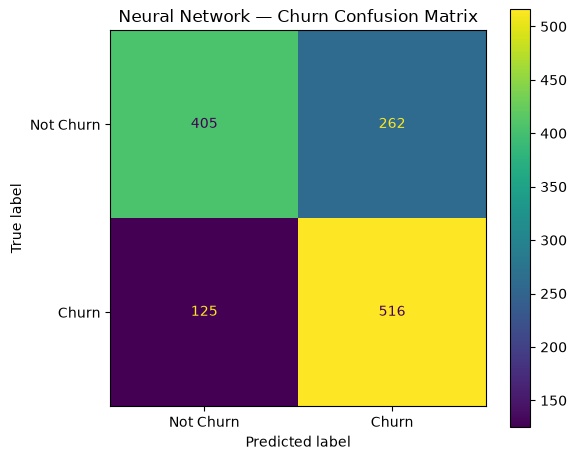

In [10]:
print('NEURAL NETWORK — CLASSIFICATION REPORT')
print(classification_report(y_test, nn_pred, digits=4, zero_division=0))

nn_cm = confusion_matrix(y_test, nn_pred)
print('Confusion Matrix:')
print(nn_cm)
print('ROC-AUC:', roc_auc_score(y_test, nn_prob))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=nn_cm,
    display_labels=['Not Churn', 'Churn']
).plot(ax=ax)
ax.set_title('Neural Network — Churn Confusion Matrix')
plt.tight_layout()
plt.show()


## 9. ROC curves for all three models


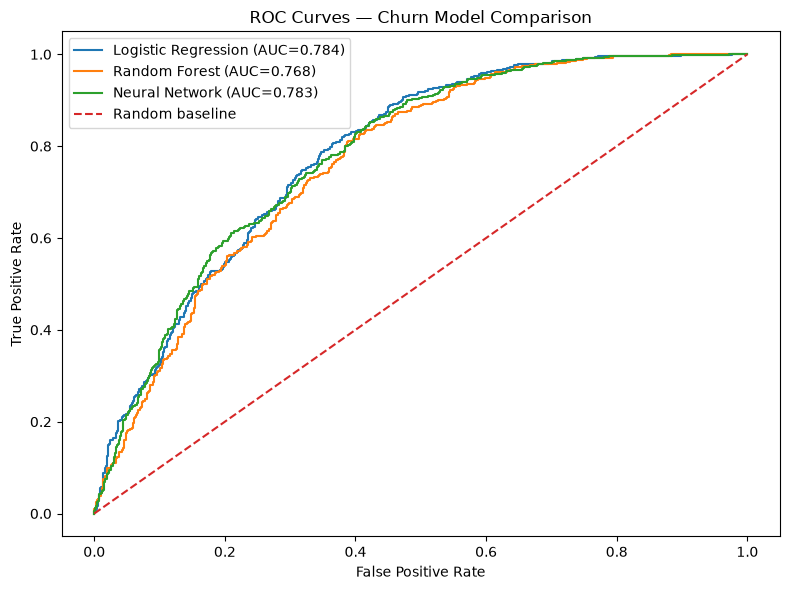

In [11]:
fpr_log, tpr_log, _ = roc_curve(y_test, logistic_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
fpr_nn, tpr_nn, _ = roc_curve(y_test, nn_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_log, tpr_log,
    label=f'Logistic Regression (AUC={roc_auc_score(y_test, logistic_prob):.3f})'
)
plt.plot(
    fpr_rf, tpr_rf,
    label=f'Random Forest (AUC={roc_auc_score(y_test, rf_prob):.3f})'
)
plt.plot(
    fpr_nn, tpr_nn,
    label=f'Neural Network (AUC={roc_auc_score(y_test, nn_prob):.3f})'
)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Churn Model Comparison')
plt.legend()
plt.tight_layout()
plt.show()


## 10. Model selection and Deep Learning conclusion

Do not select a model using Accuracy alone. Use F1-score and ROC-AUC together with the business objective of identifying churn.


In [12]:
best_name = results.loc[0, 'Model']
best_row = results.loc[0]

print('Best model by F1, with ROC-AUC as the secondary criterion:', best_name)
print(f"F1-score: {best_row['F1']:.4f}")
print(f"ROC-AUC: {best_row['ROC-AUC']:.4f}")

nn_row = results[results['Model'] == 'Neural Network'].iloc[0]
print('\nNeural Network:')
print(nn_row)

print('''
Write 2–3 sentences for the report:
The Neural Network achieved [F1] F1 and [ROC-AUC] ROC-AUC, compared with [best traditional model].
Because this is a relatively small tabular dataset, Deep Learning is [worthwhile/not worthwhile]
if its performance is [better/similar/lower] while considering the additional complexity and training overhead.
''')


Best model by F1, with ROC-AUC as the secondary criterion: Logistic Regression
F1-score: 0.7432
ROC-AUC: 0.7844

Neural Network:
Model        Neural Network
Accuracy             0.7041
Precision            0.6632
Recall               0.8050
F1                   0.7273
ROC-AUC              0.7834
Name: 2, dtype: object

Write 2–3 sentences for the report:
The Neural Network achieved [F1] F1 and [ROC-AUC] ROC-AUC, compared with [best traditional model].
Because this is a relatively small tabular dataset, Deep Learning is [worthwhile/not worthwhile]
if its performance is [better/similar/lower] while considering the additional complexity and training overhead.



## 11. Save the neural-network pipeline

The Streamlit application will use the selected churn model from Task D. This neural-network file is saved separately so Task E is reproducible and documented.


In [13]:
MODEL_DIR = Path.cwd() / 'models'
MODEL_DIR.mkdir(exist_ok=True)

nn_model_path = MODEL_DIR / 'neural_network_churn.pkl'
joblib.dump(neural_network, nn_model_path)

print('Saved:', nn_model_path.resolve())
print('File exists:', nn_model_path.exists())


Saved: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\models\neural_network_churn.pkl
File exists: True


## Task E checklist

- [ ] Same churn dataset as Task D
- [ ] Same test split
- [ ] Feed-forward neural network
- [ ] 32 → 16 → 1 architecture
- [ ] ReLU hidden layers
- [ ] Binary classification output/loss
- [ ] Accuracy, Precision, Recall, F1
- [ ] Confusion Matrix
- [ ] ROC-AUC
- [ ] Comparison with Logistic Regression and Random Forest
- [ ] 2–3 sentence Deep Learning conclusion
- [ ] Neural-network pipeline saved
